# BTL02 - Nhận Diện Cảm Xúc Khuôn Mặt (Facial Emotion Recognition - FER2013)
## Task T0105: Khám phá Dữ liệu (Exploratory Data Analysis - EDA)

- **Mã Task**: `T0105`
- **Gói công việc**: `WP1 - Hạ tầng & Dữ liệu`
- **Mục tiêu**:
  1. Đọc và kiểm tra tính toàn vẹn cấu trúc của bộ dữ liệu thô `data/raw/fer2013.csv`.
  2. Thống kê phân bố số lượng mẫu 7 lớp cảm xúc trên 3 phân tập (`Training`, `PublicTest`, `PrivateTest`).
  3. Trực quan hóa và phân tích hiện tượng mất cân bằng lớp nghiêm trọng (Severe Class Imbalance), đặc biệt giữa lớp `Happy` (8.989 mẫu) và `Disgust` (547 mẫu).
  4. Trực quan hóa lưới ảnh mẫu khuôn mặt $3 \times 7$ đại diện cho từng lớp cảm xúc.
  5. Tính toán bộ tham số chuẩn hóa (Mean và Std) trên tập Huấn luyện (Training set) để cung cấp cho `src/data/transforms.py`.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Thiết lập đường dẫn thư mục gốc dự án
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.train.utils import seed_everything

# Khóa cứng random seed = 42 theo chuẩn tái lập của AGENTS.md
seed_everything(42)

# Cấu hình thẩm mỹ đồ thị matplotlib
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

# Ánh xạ chuẩn 7 lớp nhãn FER2013
EMOTION_MAP = {
    0: 'Angry',
    1: 'Disgust',
    2: 'Fear',
    3: 'Happy',
    4: 'Sad',
    5: 'Surprise',
    6: 'Neutral'
}

RAW_DATA_PATH = project_root / 'data' / 'raw' / 'fer2013.csv'
FIGURES_DIR = project_root / 'outputs' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root}")
print(f"Raw data path: {RAW_DATA_PATH} (Exists: {RAW_DATA_PATH.exists()})")
print(f"Figures output dir: {FIGURES_DIR}")


Project root: D:\HOCTAP\repo\Deep_Learning_Group\BTL02
Raw data path: D:\HOCTAP\repo\Deep_Learning_Group\BTL02\data\raw\fer2013.csv (Exists: True)
Figures output dir: D:\HOCTAP\repo\Deep_Learning_Group\BTL02\outputs\figures


### 1. Tải và Kiểm Tra Cấu Trúc Dữ Liệu Thô `fer2013.csv`
Tệp tin `fer2013.csv` bao gồm 35.887 mẫu ảnh xám kích thước $48 \times 48$ với 3 trường thông tin:
- `emotion`: Nhãn cảm xúc (giá trị nguyên từ 0 đến 6).
- `pixels`: Chuỗi 2.304 ký tự số cách nhau bởi dấu cách ($48 \times 48 = 2.304$ pixels, giá trị 0-255).
- `Usage`: Phân tập dữ liệu ban đầu gồm `Training`, `PublicTest` và `PrivateTest`.


In [2]:
df = pd.read_csv(RAW_DATA_PATH)
print(f"Tổng số dòng và cột: {df.shape}")
print("\nThông tin chi tiết kiểu dữ liệu:")
df.info()

print("\nKiểm tra giá trị khuyết thiếu (Missing/Null values):")
print(df.isnull().sum())

print("\n5 dòng đầu tiên của bộ dữ liệu:")
df.head()


Tổng số dòng và cột: (35887, 3)

Thông tin chi tiết kiểu dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 35887 entries, 0 to 35886
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   emotion  35887 non-null  int64
 1   pixels   35887 non-null  str  
 2   Usage    35887 non-null  str  
dtypes: int64(1), str(2)
memory usage: 287.8 MB

Kiểm tra giá trị khuyết thiếu (Missing/Null values):
emotion    0
pixels     0
Usage      0
dtype: int64

5 dòng đầu tiên của bộ dữ liệu:


,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training
3,4,24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...,Training
4,6,4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...,Training


### 2. Thống Kê Phân Bố Số Lượng Mẫu Trên Các Phân Tập
Quy ước phân chia chuẩn của FER2013:
- **`Training`**: 28.709 mẫu (~80%)
- **`PublicTest`** (Dùng làm Validation set trong huấn luyện): 3.589 mẫu (~10%)
- **`PrivateTest`** (Dùng làm Final Test set đánh giá độc lập): 3.589 mẫu (~10%)


In [3]:
df['emotion_name'] = df['emotion'].map(EMOTION_MAP)

split_order = ['Training', 'PublicTest', 'PrivateTest']
emotion_order = [EMOTION_MAP[i] for i in range(7)]

# Tạo bảng chéo thống kê số lượng mẫu
crosstab_counts = pd.crosstab(df['emotion_name'], df['Usage'])[split_order]
crosstab_counts = crosstab_counts.reindex(emotion_order)
crosstab_counts['Total'] = crosstab_counts.sum(axis=1)
crosstab_counts['Percentage (%)'] = (crosstab_counts['Total'] / len(df) * 100).round(2)

print("=== BẢNG THỐNG KÊ CHI TIẾT SỐ LƯỢNG MẪU 7 LỚP FER2013 ===")
print(crosstab_counts.to_string())

print("\n=== TỔNG SỐ LƯỢNG MẪU THEO TỪNG SPLIT ===")
split_counts = df['Usage'].value_counts()[split_order]
for split_name, count in split_counts.items():
    print(f" - {split_name:<12}: {count:>6} mẫu ({count/len(df)*100:.2f}%)")
print(f" -> TỔNG CỘNG  : {len(df):>6} mẫu")


=== BẢNG THỐNG KÊ CHI TIẾT SỐ LƯỢNG MẪU 7 LỚP FER2013 ===
Usage         Training  PublicTest  PrivateTest  Total  Percentage (%)
emotion_name                                                          
Angry             3995         467          491   4953           13.80
Disgust            436          56           55    547            1.52
Fear              4097         496          528   5121           14.27
Happy             7215         895          879   8989           25.05
Sad               4830         653          594   6077           16.93
Surprise          3171         415          416   4002           11.15
Neutral           4965         607          626   6198           17.27

=== TỔNG SỐ LƯỢNG MẪU THEO TỪNG SPLIT ===
 - Training    :  28709 mẫu (80.00%)
 - PublicTest  :   3589 mẫu (10.00%)
 - PrivateTest :   3589 mẫu (10.00%)
 -> TỔNG CỘNG  :  35887 mẫu


### 3. Trực Quan Hóa Phân Bố Lớp & Nhận Diện Mất Cân Bằng Cực Đoan
Phân tích tỷ lệ phân bố:
- Lớp **`Happy`** (Vui vẻ): Chiếm **8.989 mẫu** (25.05%) - cao nhất bộ dữ liệu.
- Lớp **`Disgust`** (Ghê tởm): Chỉ có **547 mẫu** (1.52%) - thấp nhất bộ dữ liệu.
- Chênh lệch mẫu giữa `Happy` và `Disgust` lên đến **16.4 lần** ($8.989 / 547 \approx 16.43$).

Đây là bằng chứng định lượng quan trọng cho thấy mô hình dễ bị thiên vị (bias) về các lớp đa số và dự đoán kém ở lớp thiểu số. Do đó, việc theo dõi chỉ số **Macro-F1** (tính trung bình không trọng số trên 7 lớp) là bắt buộc theo quy định của đồ án.


Đã lưu biểu đồ phân bố thành công tại: D:\HOCTAP\repo\Deep_Learning_Group\BTL02\outputs\figures\eda_distribution.png


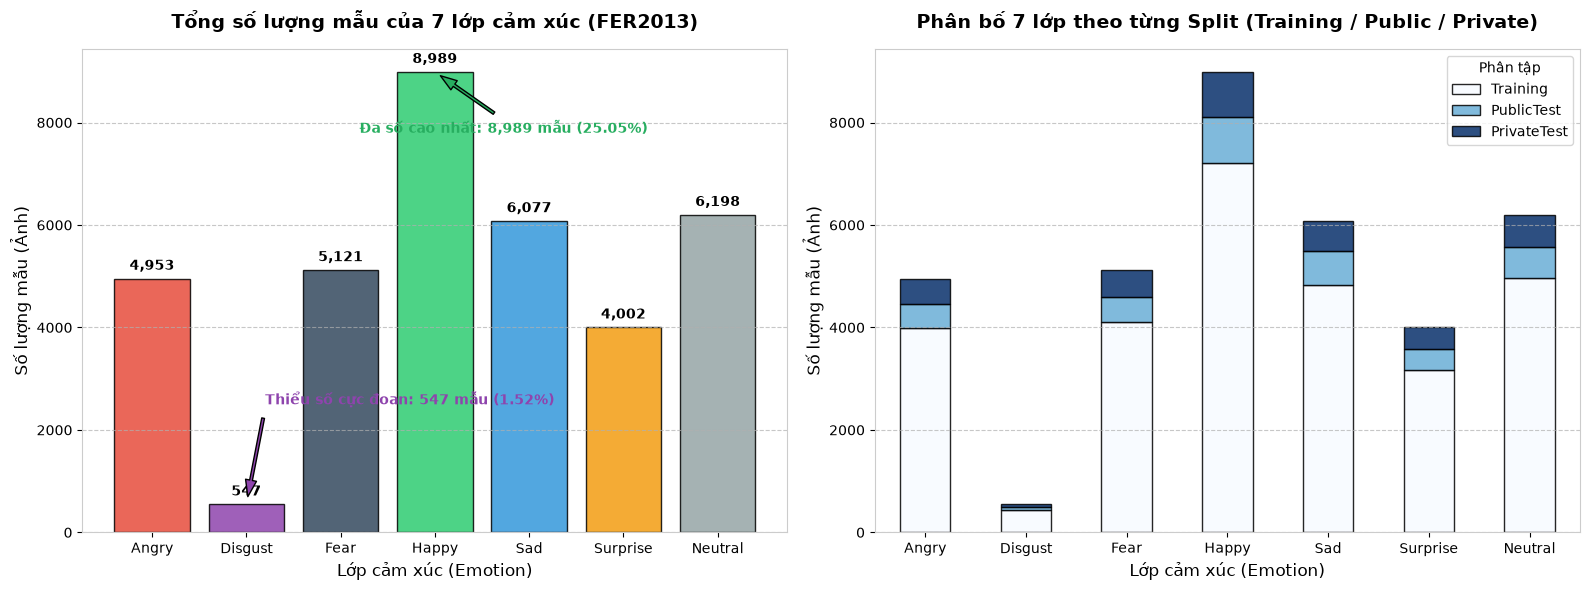

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

colors = ['#e74c3c', '#8e44ad', '#34495e', '#2ecc71', '#3498db', '#f39c12', '#95a5a6']
bars = ax1.bar(emotion_order, crosstab_counts['Total'], color=colors, alpha=0.85, edgecolor='black')

for bar in bars:
    h = bar.get_height()
    ax1.annotate(f'{h:,}',
                 xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 4), textcoords='offset points',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

ax1.set_title('Tổng số lượng mẫu của 7 lớp cảm xúc (FER2013)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Lớp cảm xúc (Emotion)', fontsize=12)
ax1.set_ylabel('Số lượng mẫu (Ảnh)', fontsize=12)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# Đánh dấu chú thích mất cân bằng lớp
ax1.annotate('Thiểu số cực đoan: 547 mẫu (1.52%)',
             xy=(1, 547), xytext=(1.2, 2500),
             arrowprops=dict(facecolor='#8e44ad', shrink=0.08, width=2, headwidth=8),
             fontsize=10, fontweight='bold', color='#8e44ad')

ax1.annotate('Đa số cao nhất: 8,989 mẫu (25.05%)',
             xy=(3, 8989), xytext=(2.2, 7800),
             arrowprops=dict(facecolor='#27ae60', shrink=0.08, width=2, headwidth=8),
             fontsize=10, fontweight='bold', color='#27ae60')

# Biểu đồ theo từng phân tập
crosstab_counts[split_order].plot(kind='bar', stacked=True, ax=ax2, colormap='Blues', edgecolor='black', alpha=0.85)
ax2.set_title('Phân bố 7 lớp theo từng Split (Training / Public / Private)', fontsize=14, fontweight='bold', pad=15)
ax2.set_xlabel('Lớp cảm xúc (Emotion)', fontsize=12)
ax2.set_ylabel('Số lượng mẫu (Ảnh)', fontsize=12)
ax2.legend(title='Phân tập', frameon=True)
ax2.grid(axis='y', linestyle='--', alpha=0.7)
ax2.set_xticklabels(emotion_order, rotation=0)

plt.tight_layout()
save_path_dist = FIGURES_DIR / 'eda_distribution.png'
plt.savefig(save_path_dist, dpi=300, bbox_inches='tight')
print(f"Đã lưu biểu đồ phân bố thành công tại: {save_path_dist}")
plt.show()


### 4. Trực Quan Hóa Lưới Ảnh Mẫu Khuôn Mặt 7 Lớp Cảm Xúc ($3 \times 7$)
Mỗi lớp cảm xúc được chọn ngẫu nhiên 3 khuôn mặt trong bộ dữ liệu để kiểm tra trực quan chất lượng ảnh và độ phân giải ($48 \times 48$ grayscale).


Đã lưu lưới ảnh mẫu thành công tại: D:\HOCTAP\repo\Deep_Learning_Group\BTL02\outputs\figures\eda_sample_faces.png


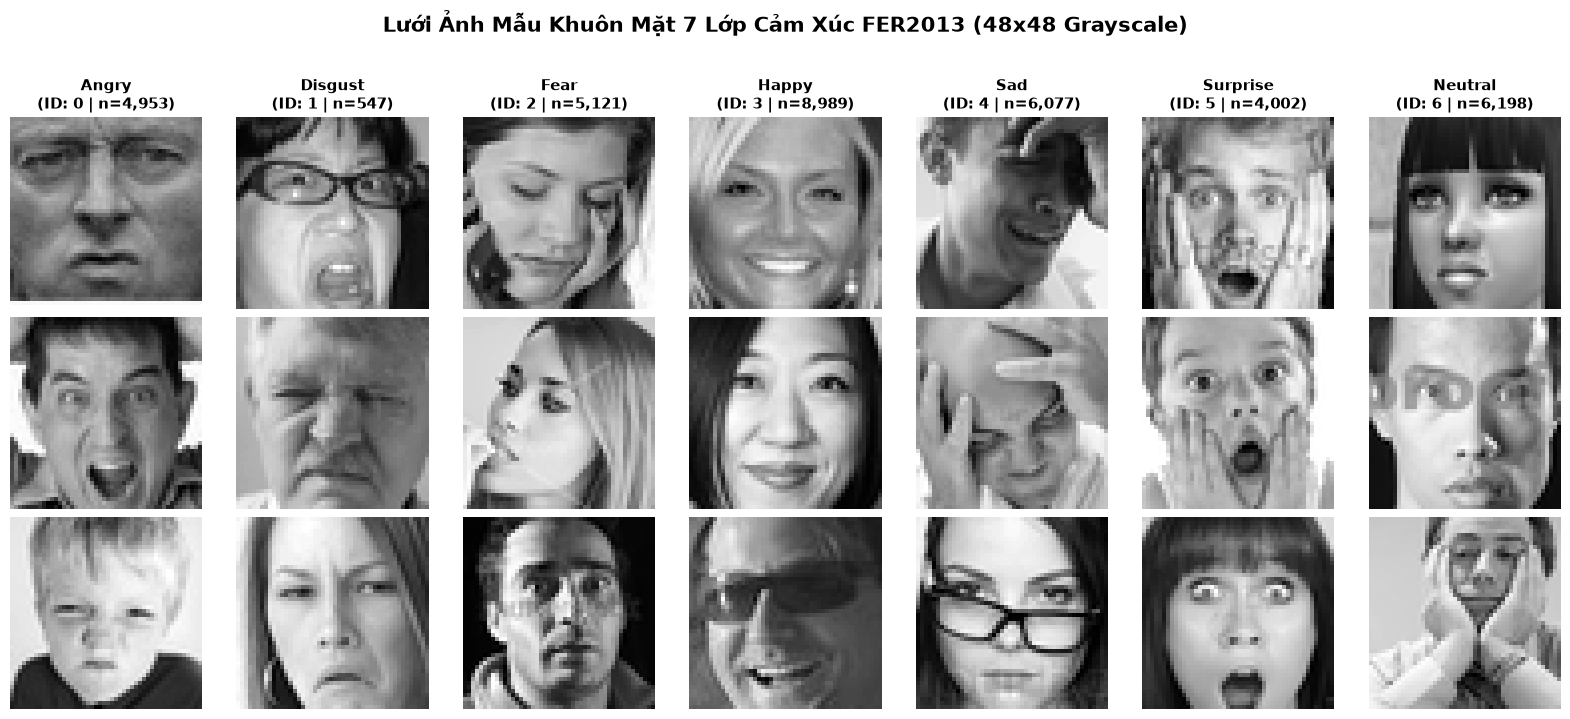

In [5]:
fig, axes = plt.subplots(3, 7, figsize=(16, 7))
np.random.seed(42)

for col_idx, (emotion_id, emotion_name) in enumerate(EMOTION_MAP.items()):
    subset = df[df['emotion'] == emotion_id]
    sample_indices = np.random.choice(len(subset), size=3, replace=False)
    
    for row_idx, idx in enumerate(sample_indices):
        ax = axes[row_idx, col_idx]
        pixel_str = subset.iloc[idx]['pixels']
        img = np.fromstring(pixel_str, dtype=np.uint8, sep=' ').reshape(48, 48)
        
        ax.imshow(img, cmap='gray')
        ax.axis('off')
        
        if row_idx == 0:
            count = len(subset)
            ax.set_title(f"{emotion_name}\n(ID: {emotion_id} | n={count:,})", fontsize=11, fontweight='bold')

plt.suptitle('Lưới Ảnh Mẫu Khuôn Mặt 7 Lớp Cảm Xúc FER2013 (48x48 Grayscale)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

save_path_faces = FIGURES_DIR / 'eda_sample_faces.png'
plt.savefig(save_path_faces, dpi=300, bbox_inches='tight')
print(f"Đã lưu lưới ảnh mẫu thành công tại: {save_path_faces}")
plt.show()


### 5. Tính Toán Chuẩn Hóa Mean & Std Cho Tập Huấn Luyện (Training Split)
Theo nguyên tắc **No Data Leakage** (Không rò rỉ dữ liệu) trong học sâu:
- Tham số chuẩn hóa $\mu$ (Mean) và $\sigma$ (Std) **chỉ được phép tính trên tập Training** (28.709 ảnh).
- Chuỗi pixel $[0, 255]$ trước tiên được chuyển đổi sang khoảng $[0.0, 1.0]$ tương ứng với toán tử `transforms.ToTensor()`.
- Kết quả thu được sẽ được đưa vào `transforms.Normalize(mean=[...], std=[...])` ở Task `T0104`.


In [6]:
train_df = df[df['Usage'] == 'Training']
print(f"Số lượng ảnh tập Training tham gia tính toán: {len(train_df):,} ảnh")

train_pixels = np.array([np.fromstring(p, dtype=np.uint8, sep=' ') for p in train_df['pixels']])
train_pixels_normalized = train_pixels.astype(np.float32) / 255.0

mean_val = float(np.mean(train_pixels_normalized))
std_val = float(np.std(train_pixels_normalized))

print("=" * 60)
print("🔥 KẾT QUẢ CHUẨN HÓA ĐẶC TRƯNG TẬP TRAINING (FER2013):")
print(f"   - Pixel Mean : {mean_val:.6f} (xấp xỉ: {mean_val:.4f})")
print(f"   - Pixel Std  : {std_val:.6f} (xấp xỉ: {std_val:.4f})")
print("=" * 60)
print("\nĐịnh dạng cấu hình áp dụng cho torchvision.transforms ở Task T0104:")
print(f"transforms.Normalize(mean=[{mean_val:.4f}], std=[{std_val:.4f}])")


Số lượng ảnh tập Training tham gia tính toán: 28,709 ảnh


🔥 KẾT QUẢ CHUẨN HÓA ĐẶC TRƯNG TẬP TRAINING (FER2013):
   - Pixel Mean : 0.507743 (xấp xỉ: 0.5077)
   - Pixel Std  : 0.255009 (xấp xỉ: 0.2550)

Định dạng cấu hình áp dụng cho torchvision.transforms ở Task T0104:
transforms.Normalize(mean=[0.5077], std=[0.2550])


### 6. Tổng Kết và Khuyến Nghị Cho Các Work Package Tiếp Theo
1. **Chất lượng dữ liệu:** File `fer2013.csv` hoàn chỉnh, đúng 35.887 mẫu, không có dòng rỗng hay giá trị khuyết thiếu.
2. **Chiến lược xử lý mất cân bằng lớp:**
   - Lớp `Disgust` có số lượng cực thấp (547 mẫu, 1.52%). Cần đặc biệt chú trọng ở Task `T0402` (Focal Loss / Class Weighted CrossEntropyLoss).
   - Chỉ số đánh giá chính thức bắt buộc phải sử dụng **Macro-F1** song song với **Accuracy**.
3. **Tiền xử lý đầu vào:**
   - Áp dụng `transforms.Normalize(mean=[0.5077], std=[0.2550])` cho cả 3 tập `Training`, `PublicTest`, `PrivateTest`.
   - **Tuyệt đối không áp dụng Data Augmentation lên tập `PublicTest` và `PrivateTest`** theo nguyên tắc hiến pháp của dự án.
